> Copyright 2019 Google Inc.
>
> Código traduzido e adaptado de https://github.com/google-research

# Previsão de sentimento em críticas de filmes com BERT no TF Hub

Se você tem acompanhado a área de Processamento de Linguagem Natural (*Natural Language Processing, NLP*) no último ano, provavelmente já ouviu falar do BERT (*Bidirectional Encoder Representations from Transformers*). Trata-se de uma arquitetura de rede neural desenvolvida por pesquisadores da Google que revolucionou o estado da arte em tarefas de NLP, como classificação de texto, tradução, sumarização e resposta a perguntas.

Agora que o BERT foi disponibilizado no Hugging Face como um módulo carregável, é relativamente fácil integrá-lo a *pipelines* de texto. Além disso, o ajuste fino (*fine-tunning*) do BERT pode proporcionar tanto um aumento na precisão quanto tempos de treinamento ais curtos em muitos casos.

A evolução dos modelos de processamento de linguagem natural parte das redes neurais recorrentes (RNNs), evoluindo para arquiteturas LSTM e Bi-LSTM, posteriormente combinadas com mecanismos de atenção e estruturas encoder-decoder. Essa trajetório culmina na arquitetura Transformer, que substitui a recorrência por mecanismos de atenção, permitindo maior paralelização e melhor modelagem das dependências de longo alcance. Assim, o modelo empregado nesta etapa representa um avanço significativo em relação às arquiteturas RNN, LSTM e Bi-LSTM apresentadas anteriormente. A Figura 1 a seguir apresenta, de forma simplificada, essa progressão arquitetural e posiciona o BERT no contexto dos modelos abordados ao longo dos experimentos.

<figure style="text-align: center;">
  <img src="assets/figura-4.png" alt="Figura 4" width="800">
</figure>

**Figura 1** – Evolução das arquiteturas de processamento de sequências até o BERT.

Aqui, treinaremos um modelo para prever se uma crítica de filme do IMDB é positiva ou negativa, usando o mesmo conjunto de dados que foi trabalhando nos últimos laboratórios, só que dessa vez utilizando a arquitetura do BERT.

In [1]:
# !python -m pip install keras-hub

In [2]:
import os
import re
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
import keras_hub
from transformers import BertTokenizer
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix

C:\Users\alyss\Desktop\dl-labs-ufcg\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# diretório para salvar os arquivos do modelo
OUTPUT_DIR = Path("output")

# se True, apaga o diretório existente antes de criar um novo
DO_DELETE = False

if DO_DELETE and OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Importando os Dados

Primeiro, vamos baixar o conjunto de dados hospedados pela Stanford, uma forma diferente até então de como o conjunto de dados foi importado nos outros laboratórios. O código a seguir baixa, extrai e importa o *IMDB Large Movie Review Dataset*.

In [4]:
# carrega todos os arquivos de um diretório em um DataFrame
def load_directory_data(directory):
    data = {}
    data["sentence"] = []
    data["sentiment"] = []

    for file_path in os.listdir(directory):
        with open(os.path.join(directory, file_path), "r", encoding="utf-8") as f:
            data["sentence"].append(f.read())

        data["sentiment"].append(re.match(r"\d+_(\d+)\.txt", file_path).group(1))

    return pd.DataFrame.from_dict(data)

# concatena exemplos positivos e negativos, adiciona uma coluna de polaridade e embaralha
def load_dataset(directory):
    pos_df = load_directory_data(os.path.join(directory, "pos"))

    neg_df = load_directory_data(os.path.join(directory, "neg"))

    pos_df["polarity"] = 1
    neg_df["polarity"] = 0

    return pd.concat(
        [pos_df, neg_df], ignore_index=True
    ).sample(frac=1,random_state=42).reset_index(drop=True)

# baixa e processa os arquivos em um diretório
def download_and_load_datasets(force_download=False):

    dataset = tf.keras.utils.get_file(
        fname="aclImdb.tar.gz",
        origin="https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz",
        extract=True
    )

    dataset_dir = os.path.join(os.path.dirname(dataset), "aclImdb_extracted", "aclImdb")

    train_df = load_dataset(os.path.join(dataset_dir, "train"))

    test_df = load_dataset(os.path.join(dataset_dir, "test"))

    return train_df, test_df

In [5]:
train, test = download_and_load_datasets()

Para manter o treinamento rápido, utilizaremos uma amostra de 5.000 exemplos de treino e de teste, respectivamente.

In [18]:
train = train.sample(5000)
test = test.sample(5000)

In [19]:
train.columns

Index(['sentence', 'sentiment', 'polarity'], dtype='str')

Os dados de entrada são a coluna `sentence` e o rótulo é a coluna `polarity` (0 e 1 para negativo e positivo, respectivamente).

In [20]:
DATA_COLUMN = 'sentence'
LABEL_COLUMN = 'polarity'
# label_list é a lista de rótulos, isto é, True, False ou 0, 1
label_list = [0, 1]

## Processamento de Dados

Nesta etapa, os dados são separados em duas componentes: textos, que correspondem às resenhas utilizadas como entrada do modelo, e rótulos, que representam a polaridade de cada resenha. De modo que o texto possa ser posteriormente processado pelo tokenizador BERT, enquanto os rótulos são utilizados como variável-alvo durante o treinamento supervisionado.

Os textos são convertidos para `str` e armazenados em listas Python por meio de `tolist()`. Já os rótulos são convertidos para o tipo inteiro `int32` e armazenados como arrays NumPy. A mesma operação é realizada para os conjuntos de treinamento e teste. 

In [21]:
# separa textos e rótulos para treinamento e teste
train_texts = train[DATA_COLUMN].astype(str).tolist()
train_labels = train[LABEL_COLUMN].astype("int32").to_numpy()

test_texts = test[DATA_COLUMN].astype(str).tolist()
test_labels = test[LABEL_COLUMN].astype("int32").to_numpy()

print(f"Dados de treinamento: {len(train_texts)}")
print(f"Dados de teste: {len(test_texts)}")

Dados de treinamento: 5000
Dados de teste: 5000


Nesta etapa, é carregado o tokenizador pré-treinado do BERT Base Uncased. O texto de exemplo é então dividido em *tokens* utilizando o vocabulário e as regras de tokenização do BERT, incluindo a possibilidade de decompor palavras desconhecidas em *subword tokens*.

In [22]:
tokenizer = BertTokenizer.from_pretrained(
    "bert-base-uncased"
)

In [23]:
text = "This here's an example of using the BERT tokenizer"

tokens = tokenizer.tokenize(text)

print(tokens)

['this', 'here', "'", 's', 'an', 'example', 'of', 'using', 'the', 'bert', 'token', '##izer']


As resenhas são convertidas em representações compatíveis com o BERT por meio do tokenizador previamente carregado. É definido um comprimento máximo de 128 tokens por sequência. Resenhas maiores são truncadas, enquanto sequências menores são preenchidas (*padding*) até esse tamanho.

O resultado é armazenado como arrays NumPy, contendo as informações necessárias para alimentar o modelo, como os identificadores dos tokens, os identificadores de segmento e a máscara de atenção.

In [24]:
# define o tamanho máximo das sequências
MAX_SEQ_LENGTH = 128

# tokeniza as resenhas de treinamento
train_features = tokenizer(
    train_texts,
    max_length=MAX_SEQ_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="np"
)

# tokeniza as resenhas de teste
test_features = tokenizer(
    test_texts,
    max_length=MAX_SEQ_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="np"
)

## Criando o Modelo

<figure style="text-align: center;">
  <img src="assets/figura-5.png" alt="Figura 2" width="800">
</figure>

**Figura 2** – Arquitetura BERT para o problema de análise de sentimentos nas *reviews* do IMDB.

As três entradas produzidas pela tokenização (`padding_mask`, `segment_ids` e `token_ids`), restritas ao comprimento de 128 posições, alimentam diretamente o *backbone* pré-treinado do BERT.

Do ponto de vista estrutural, a visualização evidencia que o peso computacional da rede recai quase inteiramente no bloco do BERT, responsável por processar a sequência utilizando 109.482.240 parâmetros. O `pooled_output` resultante atua como um extrator de características, comprimindo o contexto semântico da resenha em um vetor de dimensão 768. 

Após a aplicação do *dropout* com taxa de 0.1 como regularizador, a rede culmina em uma camada classificadora densa leve, contendo apenas 1.538 parâmetros. Essa camada é responsável por projetar as características diretamente nos dois *logits* de saída (para as classes Negativa e Positiva). 

In [25]:
# carrega o backbone bert-base-uncased pré-treinado
bert_backbone = keras_hub.models.BertBackbone.from_preset(
    "bert_base_en_uncased"
)

Nesta etapa são definidos os principais hiperparâmetros utilizados no ajuste fino do BERT. O treinamento utiliza *batches* de 32 exemplos, taxa de aprendizado de $2.10^{-5}$ e 3 épocas.

Também é definida uma proporção de 10% dos passos de treinamento para warmup, estratégia na qual a taxa de aprendizado é gradualmente aumentada no início do treinamento. Por fim, como o problema consiste em classificação binária de sentimentos, são consideradas duas classes: negativa e positiva.

In [26]:
# hiperparâmetros de treinamento
BATCH_SIZE = 32
LEARNING_RATE = 2e-5
NUM_TRAIN_EPOCHS = 3

# proporção do treinamento utilizada para warmup
WARMUP_PROPORTION = 0.1

# número de classes
NUM_LABELS = 2

In [27]:
# número de passos de treinamento
num_train_steps = int(
    len(train_labels) / BATCH_SIZE * NUM_TRAIN_EPOCHS
)

# número de passos de warmup
num_warmup_steps = int(
    num_train_steps * WARMUP_PROPORTION
)

print("Train steps:", num_train_steps)
print("Warmup steps:", num_warmup_steps)

Train steps: 468
Warmup steps: 46


A seguir, serão configurados *callbacks* para acompanhar e preservar os resultados do treinamento. O `ModelCheckpoint` salva uma cópia do modelo ao final de cada época, permitindo recuperar posteriormente o estado treinado sem necessidade de executar o treinamento novamente.

In [28]:
# callback para salvar o modelo a cada época
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(OUTPUT_DIR / "bert_checkpoint.keras"),
    save_weights_only=False,
    save_freq="epoch"
)

# callback para registrar métricas no tensorboard
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=str(OUTPUT_DIR / "logs")
)

Nesta etapa é construída a arquitetura utilizada para a classificação de sentimentos. O modelo recebe três entradas produzidas durante a tokenização: `token_ids`, que identificam os tokens da sequência; `segment_ids`, que identificam os segmentos; e `padding_mask`, que indica quais posições correspondem a tokens reais e quais foram adicionadas por preenchimento.

As entradas são processadas pelo modelo BERT pré-treinado, a partir do qual é extraído o `pooled_output`, uma representação vetorial contextualizada da sequência. Essa representação é encaminhada para uma camada de *dropout* com taxa de 10%, utilizada como mecanismo de regularização, e posteriormente para uma camada `Dense` com duas saídas, correspondentes às classes de nosso interessse: Negative e Positive.

A função de perda utilizada é a `SparseCategoricalCrossentropy` com `from_logits=True`, adequada para classificação multiclasse quando a última camada fornece *logits* diretamente, sem aplicação prévia de `softmax`. O otimizador Adam utiliza a taxa de aprendizado definida anteriormente ($2.10^{-5}$), enquanto a acurácia é utilizada como métrica de avaliação durante o treinamento.

In [29]:
# número de classes
NUM_LABELS = len(label_list)

# cria o modelo BERT para classificação
inputs = {
    "token_ids": keras.Input(
        shape=(MAX_SEQ_LENGTH,),
        dtype="int32",
        name="token_ids"
    ),
    "segment_ids": keras.Input(
        shape=(MAX_SEQ_LENGTH,),
        dtype="int32",
        name="segment_ids"
    ),
    "padding_mask": keras.Input(
        shape=(MAX_SEQ_LENGTH,),
        dtype="bool",
        name="padding_mask"
    )
}
# passa as entradas pelo BERT
bert_outputs = bert_backbone(inputs)

# representação da sequência
pooled_output = bert_outputs["pooled_output"]

# dropout
x = keras.layers.Dropout(0.1)(pooled_output)

# camada de classificação
outputs = keras.layers.Dense(
    NUM_LABELS,
    name="classifier"
)(x)

# modelo completo
model = keras.Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, 128)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ segment_ids (InputLayer)      │ (None, 128)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, 128)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bert_backbone (BertBackbone)  │ [(None, 768), (None, 128, │     109,482,240 │ padding_mask[0][0],        │
│                               │ 768)]                     │                 │ segment_ids[0][0],         │
│                               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_25 (Dropout)          │ (None, 768)               │               0 │ bert_backbone[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ classifier (Dense)            │ (None, 2)                 │           1,538 │ dropout_25[0][0]           │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 109,483,778 (417.65 MB)

 Trainable params: 109,483,778 (417.65 MB)

 Non-trainable params: 0 (0.00 B)

As estruturas produzidas pelo tokenizador Hugging Face utilizam nomes de campos diferentes dos esperados pelo `BertBackbone` do KerasHub. Nesta etapa, é realizado o mapeamento entre essas representações.

| Hugging Face | KerasHub | Função |
|---|---|---|
| `input_ids` | `token_ids` | Identificadores dos tokens |
| `token_type_ids` | `segment_ids` | Identificadores dos segmentos |
| `attention_mask` | `padding_mask` | Indica tokens válidos e posições de preenchimento |

In [30]:
# converte as saídas do tokenizer Hugging Face para os nomes esperados pelo KerasHub.
train_x = {
    "token_ids": train_features["input_ids"],
    "segment_ids": train_features["token_type_ids"],
    "padding_mask": train_features["attention_mask"].astype(bool)
}

test_x = {
    "token_ids": test_features["input_ids"],
    "segment_ids": test_features["token_type_ids"],
    "padding_mask": test_features["attention_mask"].astype(bool)
}

print("Train:")
for key, value in train_x.items():
    print(f"{key}: {value.shape}")

print("\nTest:")
for key, value in test_x.items():
    print(f"{key}: {value.shape}")

Train:
token_ids: (5000, 128)
segment_ids: (5000, 128)
padding_mask: (5000, 128)

Test:
token_ids: (5000, 128)
segment_ids: (5000, 128)
padding_mask: (5000, 128)


Nesta etapa, os dados de entrada e seus respectivos rótulos são organizados em um `tf.data.Dataset`, estrutura utilizada pelo TensorFlow para fornecer os exemplos ao modelo durante o treinamento.

Os exemplos são inicialmente embaralhados (`shuffle`) para reduzir possíveis efeitos relacionados à ordem dos dados. Em seguida, são agrupados em *batches* de tamanho definido por `BATCH_SIZE`. O parâmetro `drop_remainder=False` garante que, caso o número total de exemplos não seja divisível pelo tamanho do *batch*, o último grupo de exemplos também seja utilizado.

Por fim, `prefetch(tf.data.AUTOTUNE)` permite que o TensorFlow prepare os próximos *batches* enquanto o modelo processa o atual.

In [31]:
# cria o dataset de treinamento
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_x, train_labels)
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(train_labels)
)

train_dataset = train_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)

Como o ajuste fino (*fine-tuning*) do BERT possui um custo computacional elevado, o treinamento foi realizado previamente. Nesta etapa, o arquivo do modelo é baixado por meio do Google Drive. O treinamento permanece comentado para evitar uma nova execução desnecessária. Após o download, `keras.models.load_model()` restaura o modelo completo, incluindo a arquitetura e os parâmetros obtidos durante o *fine-tuning*. A partir desse ponto, o modelo pode ser utilizado diretamente para avaliação, classificação de novas resenhas e análise das representações latentes. Para realizar o treinamento novamente, descomente o bloco de treinamento e comente a etapa de carregamento do modelo previamente salvo.

In [48]:
# baixe os pesos do bert treinado com fine-tuning pelo google drive
%pip install -q gdown

import gdown

FILE_ID = "11hcV3gJW-Ij6Vxq_JWM6ezEV_cp88nTH"
DATASET_ZIP = str(OUTPUT_DIR / "bert_imdb.weights.h5")

gdown.download(
    id=FILE_ID,
    output=DATASET_ZIP
)

Note: you may need to restart the kernel to use updated packages.


Downloading...
From (original): https://drive.google.com/uc?id=11hcV3gJW-Ij6Vxq_JWM6ezEV_cp88nTH
From (redirected): https://drive.google.com/uc?id=11hcV3gJW-Ij6Vxq_JWM6ezEV_cp88nTH&confirm=t&uuid=55ffdd8d-14e0-4c62-8464-a3795104abc3
To: C:\Users\alyss\Desktop\dl-labs-ufcg\lab4-transformers\output\bert_imdb.weights.h5
100%|██████████| 1.31G/1.31G [00:47<00:00, 27.5MB/s]


'output\\bert_imdb.weights.h5'

In [49]:
# treinamento comentado pois os pesos já foram salvos
# print("Beginning Training!")
# current_time = datetime.now()
# history = model.fit(
#     train_dataset,
#     epochs=NUM_TRAIN_EPOCHS,
#     callbacks=[checkpoint_callback, tensorboard_callback]
# )
# print("Training took time:", datetime.now() - current_time)

# carrega o modelo treinado salvo
model.load_weights(
    str(OUTPUT_DIR / "bert_imdb.weights.h5")
)

## Análise do Modelo

Após o treinamento e a recuperação dos pesos do modelo, esta etapa é dedicada à análise de seu desempenho e de suas representações aprendidas. Inicialmente, são avaliadas as predições realizadas sobre o conjunto de teste, utilizando métricas e a matriz de confusão para verificar a capacidade do modelo em distinguir corretamente as classes Negative e Positive.

Em seguida, são analisadas as representações obtidas pelo BERT no espaço latente. A redução de dimensionalidade por meio do t-SNE permite visualizar como as amostras das diferentes classes se distribuem nesse espaço e verificar se o modelo desenvolveu representações capazes de separar semanticamente os sentimentos.

In [50]:
# cria o dataset de teste
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_x, test_labels)
)

test_dataset = test_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

In [51]:
results = model.evaluate(
    test_dataset,
    return_dict=True
)

print(results)

157/157 ━━━━━━━━━━━━━━━━━━━━ 708s 4s/step - accuracy: 0.8616 - loss: 0.3949
{'accuracy': 0.8615999817848206, 'loss': 0.39486488699913025}


In [52]:
# retorna lista de (frase, probabilidades, rótulo) para cada entrada
def get_prediction(in_sentences):
    labels = ["Negative", "Positive"]

    # tokeniza as frases
    features = tokenizer(
        in_sentences,
        max_length=MAX_SEQ_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )

    # converte para o formato esperado pelo keras-hub
    predict_x = {
        "token_ids": features["input_ids"],
        "segment_ids": features["token_type_ids"],
        "padding_mask": features["attention_mask"].astype(bool)
    }

    # faz as previsões e converte logits em probabilidades
    logits = model.predict(predict_x, verbose=0)
    probabilities = keras.ops.softmax(logits, axis=-1)
    predicted_labels = keras.ops.argmax(probabilities, axis=-1)

    # converte para numpy
    probabilities = keras.ops.convert_to_numpy(probabilities)
    predicted_labels = keras.ops.convert_to_numpy(predicted_labels)

    return [
        (sentence, probabilities[i], labels[predicted_labels[i]])
        for i, sentence in enumerate(in_sentences)
    ]

In [53]:
my_reviews = [
    "This movie was absolutely fantastic, the acting was great and the plot was amazing.",
    "I hated this film. It was boring, slow, and a complete waste of time.",
    "The visual effects were incredible and the sound design was top tier, but the story was empty and boring.",
    "I really wanted to love this movie. The trailer looked like a masterpiece, but the actual film was a huge letdown.",
    "If you are a fan of mindless action with zero plot, this is perfect. Otherwise, stay away.",
    "Oh, brilliant. Another superhero movie with the exact same plot as the last fifty ones. Just what we needed.",
    "It was not the best movie I have ever seen, but it was certainly not the worst. It was just okay.",
    "I cannot say I didn't enjoy it. It was actually better than I expected.",
    "At first I thought this movie was going to be terrible, but the ending was absolutely perfect.",
    "Funny at times, yet I wouldn't watch it again.",
    "Nice visuals and great performances, but the plot was completely confusing, waste of time and terrible."
]

predictions = get_prediction(my_reviews)

In [54]:
# visualiza os resultados da predição
predictions

[('This movie was absolutely fantastic, the acting was great and the plot was amazing.',
  array([0.003452, 0.996548], dtype=float32),
  'Positive'),
 ('I hated this film. It was boring, slow, and a complete waste of time.',
  array([0.9975878 , 0.00241226], dtype=float32),
  'Negative'),
 ('The visual effects were incredible and the sound design was top tier, but the story was empty and boring.',
  array([0.9979133 , 0.00208672], dtype=float32),
  'Negative'),
 ('I really wanted to love this movie. The trailer looked like a masterpiece, but the actual film was a huge letdown.',
  array([0.9923596 , 0.00764038], dtype=float32),
  'Negative'),
 ('If you are a fan of mindless action with zero plot, this is perfect. Otherwise, stay away.',
  array([0.8783638 , 0.12163622], dtype=float32),
  'Negative'),
 ('Oh, brilliant. Another superhero movie with the exact same plot as the last fifty ones. Just what we needed.',
  array([0.11829524, 0.88170475], dtype=float32),
  'Positive'),
 ('It was

157/157 ━━━━━━━━━━━━━━━━━━━━ 692s 4s/step


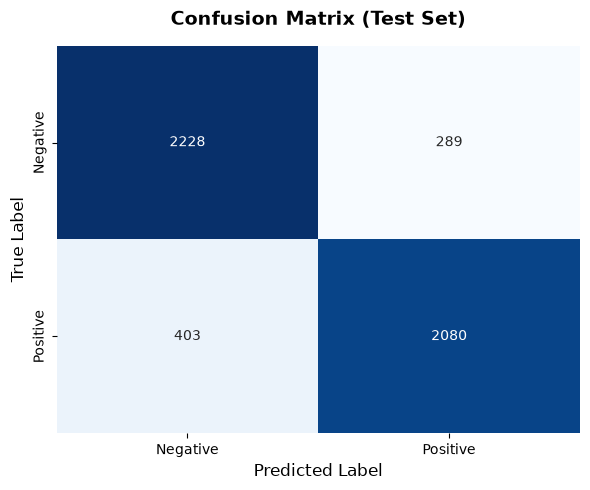

In [55]:
# faz as predições no conjunto de teste
logits = model.predict(test_x, verbose=1)

# converte logits em classes preditas
predictions = np.argmax(logits, axis=1)

# gera a matriz de confusão
cm = confusion_matrix(test_labels, predictions)

# plota a matriz de confusão
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    cbar=False
)
plt.title("Confusion Matrix (Test Set)", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("True Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.tight_layout()
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 143s 4s/step
shape da matriz latente: (1000, 768)
shape dos rótulos: (1000,)


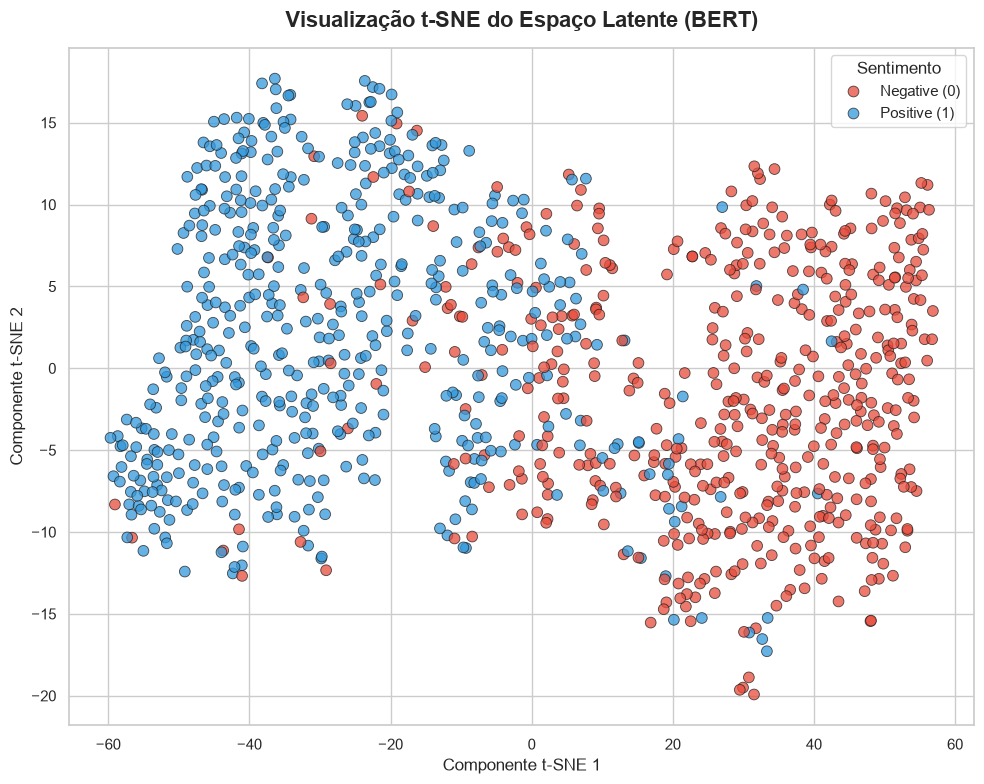

In [56]:
# modelo auxiliar para extrair o pooled output do bert
feature_extractor = keras.Model(
    inputs=model.inputs,
    outputs=pooled_output
)

# seleciona subconjunto do teste para visualização
num_samples_to_visualize = 1000
visualization_x = {
    "token_ids": test_features["input_ids"][:num_samples_to_visualize],
    "segment_ids": test_features["token_type_ids"][:num_samples_to_visualize],
    "padding_mask": test_features["attention_mask"][:num_samples_to_visualize].astype(bool)
}
labels_array = np.array(test_labels[:num_samples_to_visualize])

# extrai as representações do espaço latente
latent_matrix = feature_extractor.predict(visualization_x, verbose=1)
print(f"shape da matriz latente: {latent_matrix.shape}")
print(f"shape dos rótulos: {labels_array.shape}")

# redução de dimensionalidade com t-sne
tsne = TSNE(n_components=2, random_state=42, perplexity=30.0, max_iter=1000)
tsne_results = tsne.fit_transform(latent_matrix)

# plota o espaço latente com cores por sentimento
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(10, 8))
scatter_plot = sns.scatterplot(
    x=tsne_results[:, 0],
    y=tsne_results[:, 1],
    hue=labels_array,
    palette=["#e74c3c", "#3498db"],
    alpha=0.75,
    edgecolor="k",
    s=60
)
legend_handles, _ = scatter_plot.get_legend_handles_labels()
plt.legend(handles=legend_handles, labels=["Negative (0)", "Positive (1)"], title="Sentimento", loc="best", fontsize=11)
plt.title("Visualização t-SNE do Espaço Latente (BERT)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Componente t-SNE 1", fontsize=12)
plt.ylabel("Componente t-SNE 2", fontsize=12)
plt.tight_layout()
plt.show()